In [1]:
import os
import json
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D
import seaborn as sns

from scipy.stats import kde, kruskal
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import fdrcorrection
from scikit_posthocs import posthoc_dunn
from statannotations.Annotator import Annotator

import random
import warnings
import operator

import pickle

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, get_tx_order, format_box_plot

plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


Data prep

In [2]:
#HANN mapping
class_col = 'class_label_Hierarchical'
subclass_col = 'subclass_label_Hierarchical'
cluster_col = 'cluster_label_Hierarchical'

In [3]:
#load data# Save root 
output_dir = Path('/root/capsule/scratch') / '20260807' / 'metadata_ratio'
os.makedirs(output_dir, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

metadata_path =              DATA_ROOT / 'human'            / 'metadata'   / '20260807' / 'human_metadata.csv'

l23_ttype_rename_file =      DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'
ttype_layer_file =           DATA_ROOT / 'formatting_dicts' / 'ttype_layer_dict.json'

lobe_color_file =            DATA_ROOT / 'colors'           / 'lobe_colors.json'
paradigm_color_file =        DATA_ROOT / 'colors'           / 'paradigm_colors.json'
layer_color_file =           DATA_ROOT / 'colors'           / 'layer_colors.json'



In [4]:

# Load data
with open(l23_ttype_rename_file, "r") as f:
    L23_ttype_rename_dict = json.load(f)

with open(ttype_layer_file, "r") as f:
    ttype_to_layer_dict = json.load(f)

metadata = pd.read_csv(metadata_path)
metadata = metadata[metadata['Transcriptomics?'] == True]
metadata = metadata.rename(columns={'cell_id' : 'specimen_id', cluster_col: "t_type", subclass_col:'subclass_label'}).set_index('specimen_id')
metadata["layer"] = metadata["t_type"].map(ttype_to_layer_dict)

#split Layer 2 and 3 subclass
metadata["layer_subclass"] = metadata.apply(
    lambda row: "L2 IT" if row["layer"] == 'Layer 2'
                else ("L3 IT" if row["layer"] == 'Layer 3'
                    else row["subclass_label"]),
    axis=1
)
metadata_cols = ['t_type', 'subclass_label', 'layer_subclass', 'layer', 'lobe', 'paradigm', 'medical_conditions_simple', 'group']
metadata = metadata[metadata_cols]
metadata['lobe_group'] = metadata['lobe'].apply(lambda x: x if x == 'TemL' else 'Other')
metadata['subclass_label'] = metadata['subclass_label'].fillna('TBD')  #remove vals without a seaad mapping
metadata['t_type'] = metadata['t_type'].fillna('TBD')
metadata['subclass_label'] = metadata['subclass_label'].replace('L5 ET_ME', 'L5 ET')
metadata['subclass_label'] = metadata['subclass_label'].replace('L5 ET(ME)', 'L5 ET')
metadata['t_type'] = metadata['t_type'].replace('L5 ET_ME', 'L5 ET(ME)')
metadata['t_type'] = metadata['t_type'].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata['layer'] = metadata["t_type"].map(ttype_to_layer_dict)




In [5]:
metadata

,t_type,subclass_label,layer_subclass,layer,lobe,paradigm,medical_conditions_simple,group,lobe_group
specimen_id,,,,,,,,,
1.371205e+09,L5/6 NP_2,L5/6 NP,L5/6 NP,Layer 5,TemL,acute,other,Hungary,TemL
1.333499e+09,L2 IT_2,L2/3 IT,L2/3 IT,Layer 2,TemL,acute,other,Hungary,TemL
1.333500e+09,L4 IT_2,L4 IT,L4 IT,Layer 4,TemL,acute,other,Hungary,TemL
1.151282e+09,L2 IT_1,L2/3 IT,L2/3 IT,Layer 2,FroL,acute,other,Hungary,Other
1.217502e+09,L3 IT_5,L2/3 IT,L2/3 IT,Layer 3,FroL,acute,other,Hungary,Other
...,...,...,...,...,...,...,...,...,...
1.451265e+09,L2 IT_6,L2/3 IT,L2/3 IT,Layer 2,TemL,acute,tumor,Amsterdam,TemL
1.447136e+09,L5 IT_2,L5 IT,L5 IT,Layer 5,TemL,acute,tumor,Hungary,TemL
1.447136e+09,L2 IT_1,L2/3 IT,L2/3 IT,Layer 2,TemL,acute,tumor,Hungary,TemL


In [6]:
#Get color dicts
color_dict = get_seaad_colors()
with open(layer_color_file, "r") as f: layer_color_dict = json.load(f)
with open(lobe_color_file, "r") as f: lobe_color_dict = json.load(f)
with open(paradigm_color_file, "r") as f: paradigm_color_dict = json.load(f)

group_color_dict = dict(zip(
    metadata['group'].unique(),
    sns.color_palette("tab10", len(metadata['group'].unique())).as_hex()
))

condition_color_dict = dict(zip(
    metadata['medical_conditions_simple'].unique(),
    sns.color_palette("tab10", len(metadata['medical_conditions_simple'].unique())).as_hex()
))

color_dicts = {
    't_type' : color_dict, 
    'subclass_label' : color_dict, 
    'lobe' : lobe_color_dict, 
    'lobe_group' : lobe_color_dict,
    'paradigm' : paradigm_color_dict,
    'layer' : layer_color_dict, 
    'group' : group_color_dict,
    'medical_conditions_simple' : condition_color_dict
}


#Get custom transcriptomic order
ttype_order, subclass_order = get_tx_order()
group_order = {
    'subclass_label' : subclass_order,
    't_type' :  ttype_order,
    'lobe' : ['TemL', 'FroL'],
    'lobe_group' : ['TemL', 'Other'],
    'paradigm' : ['acute', 'culture'],
    'layer' : sorted(list(set(ttype_to_layer_dict.values()))),
    'group' : sorted(list(set(metadata.group.unique()))),
    'medical_conditions_simple' : sorted(list(set(metadata.medical_conditions_simple.unique())))

}

Visualize metadata features by subclass 

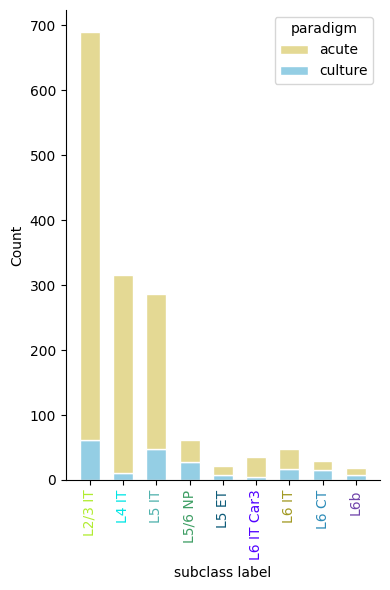

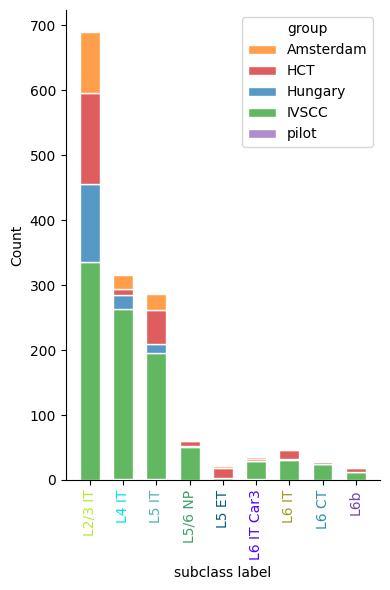

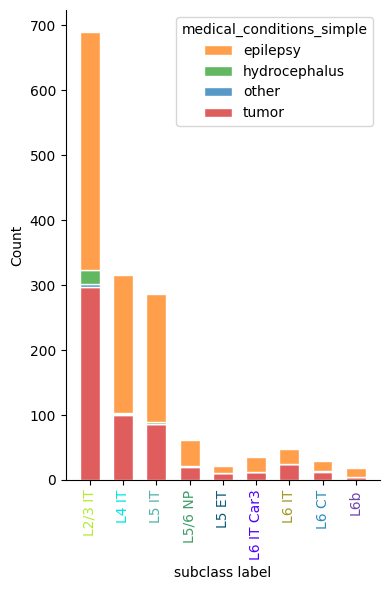

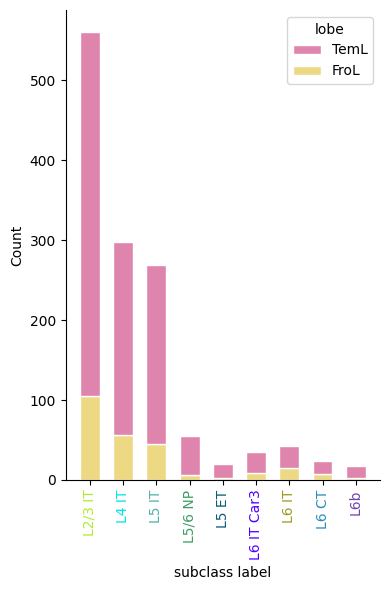

<Figure size 640x480 with 0 Axes>

In [7]:
x_var = 'subclass_label'
hue_vars = ['paradigm', 'group', 'medical_conditions_simple', 'lobe']

fig_name = f'human_excitatory_paradigm_ratios_by_{x_var}.pdf'
fig_path = os.path.join(output_dir, fig_name)
with PdfPages(fig_path) as pdf:

    for hue_var in hue_vars:

        x_colordict = color_dicts[x_var]
        x_var_order = group_order[x_var]
        hue_colordict = color_dicts[hue_var]
        hue_var_order = group_order[hue_var]

        fig, ax = plt.subplots(figsize=(4,6)) #plt.figure(figsize=(4, 6))

        plot_data = metadata.copy()

        plot_data[x_var] = pd.Categorical(
            plot_data[x_var],
            categories=x_var_order,
            ordered=True
        )

        sns.histplot(
            data=plot_data,
            ax=ax,
            x=x_var,
            hue=hue_var,
            hue_order=hue_var_order,
            multiple='stack',
            discrete=True,
            palette=hue_colordict,
            edgecolor='white',
            shrink=0.6
        )

        # Color x-axis labels using a separate color dictionary
        for label in ax.get_xticklabels():
            text = label.get_text()
            if text in x_colordict:
                label.set_color(x_colordict[text])

        # Remove top and right bounding box
        sns.despine(ax=ax, top=True, right=True)

        plt.xlabel(x_var.replace('_', ' '))
        plt.ylabel('Count')
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()

        fig.subplots_adjust(wspace=0, hspace=0.0)
        pdf.savefig(fig, dpi=600, bbox_inches='tight')

    plt.show()
    plt.clf()
    print()

Visualize metadata features by supertype

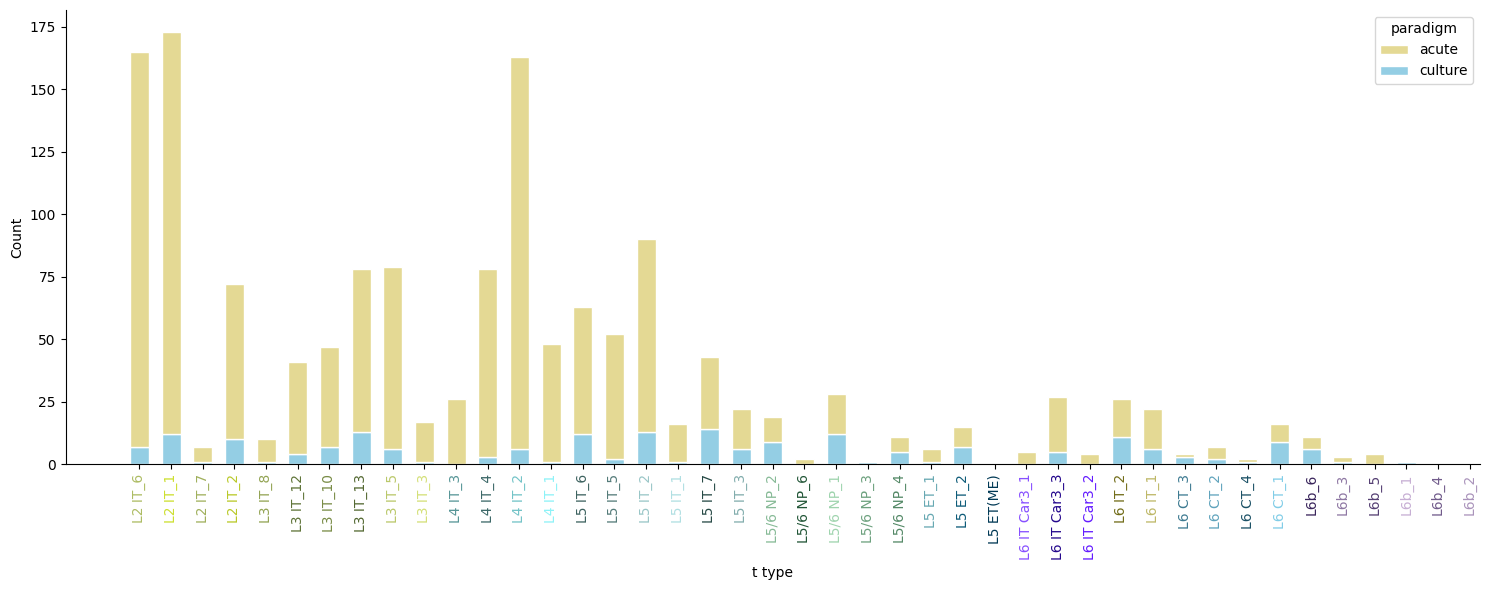

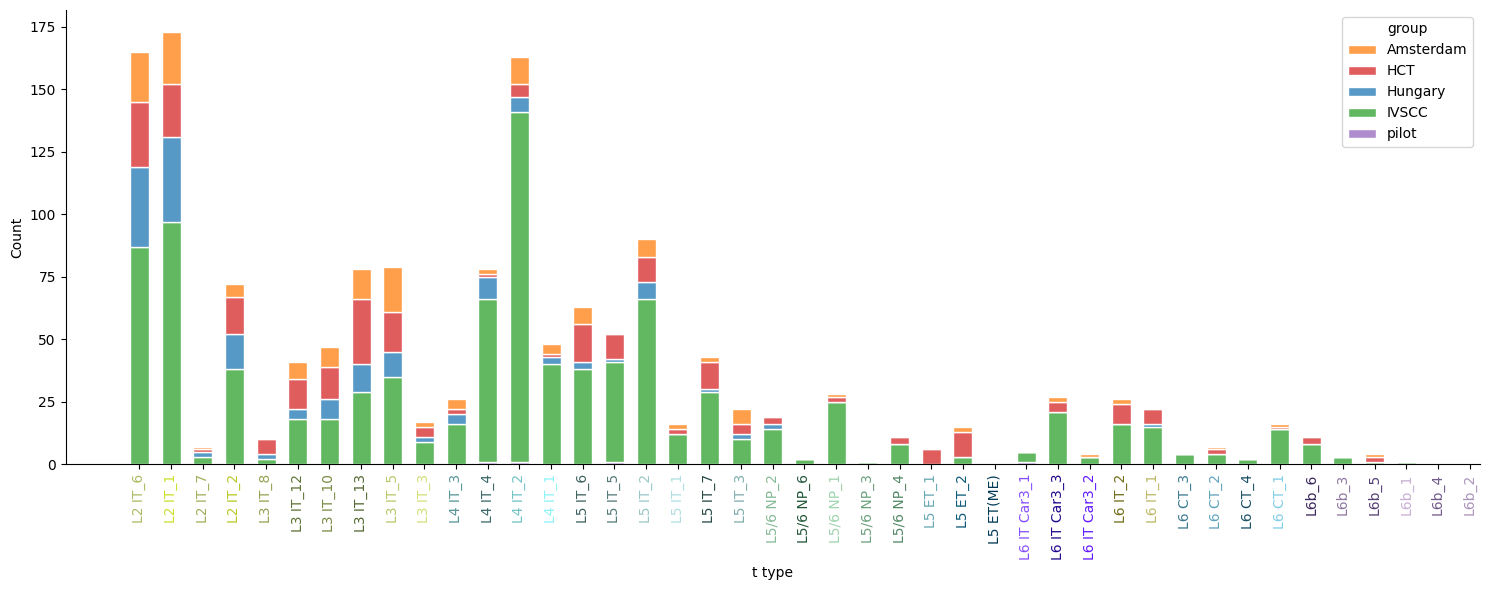

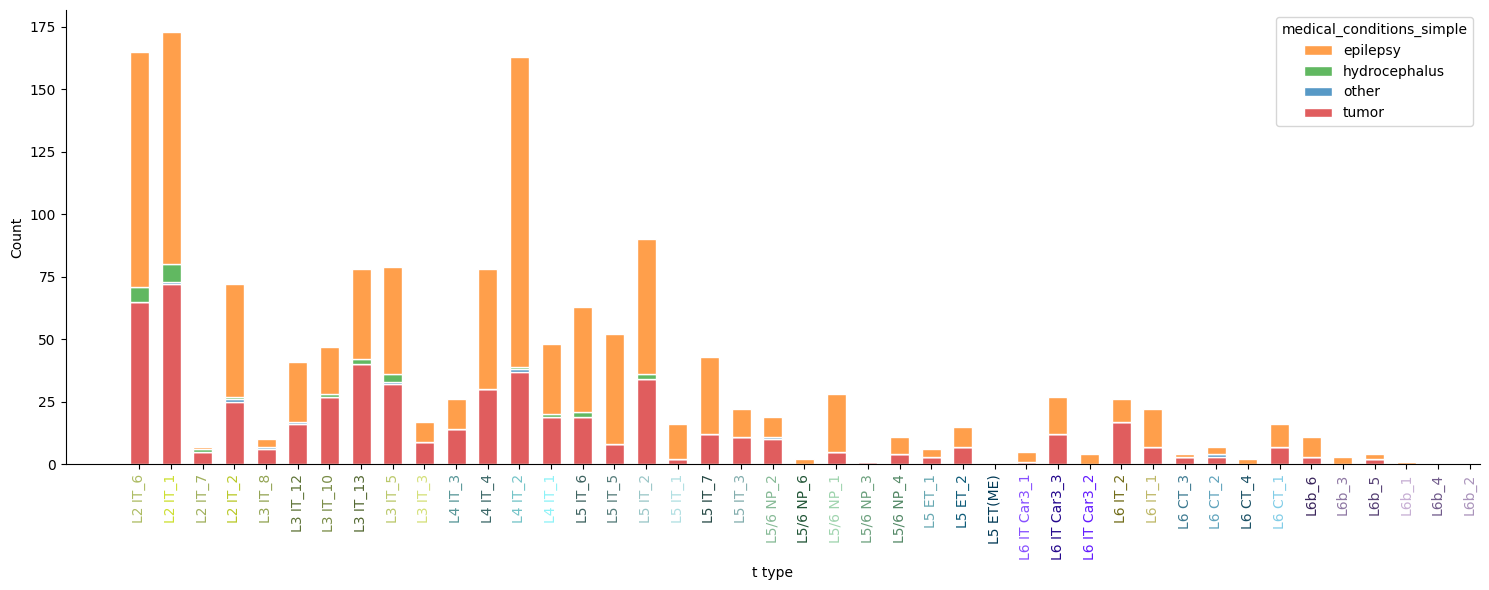

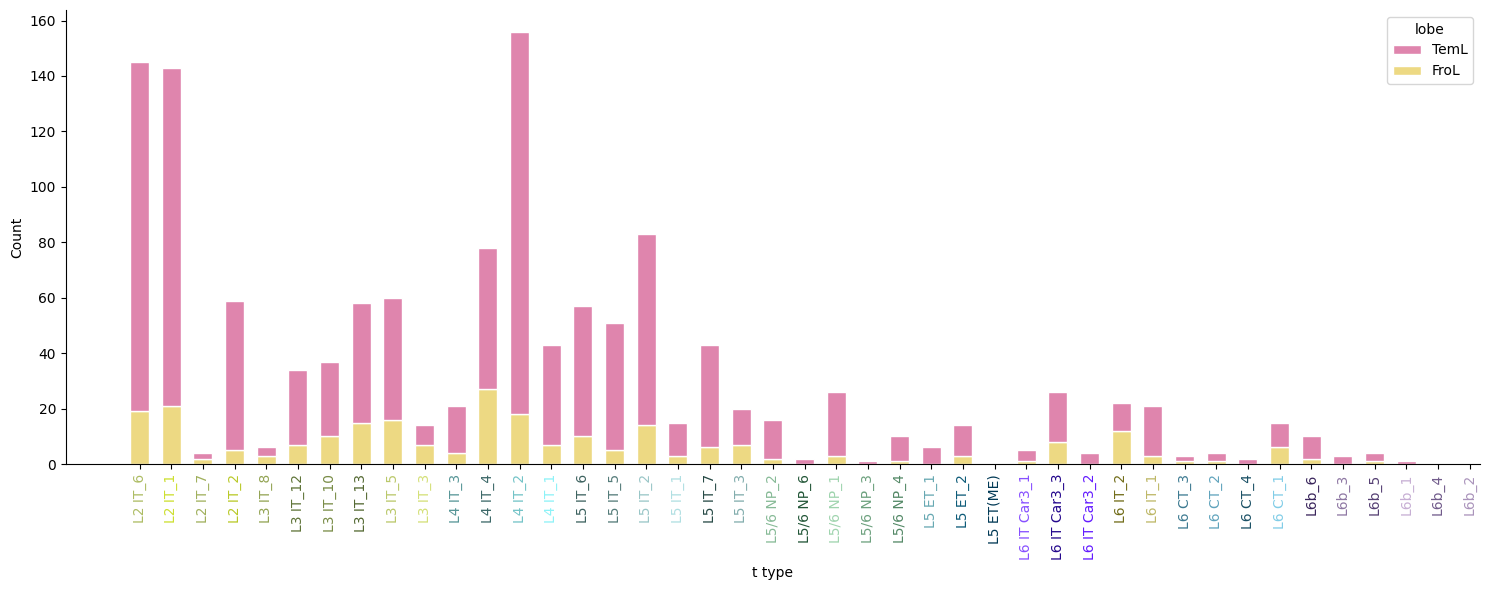

<Figure size 640x480 with 0 Axes>

In [8]:
x_var = 't_type'
hue_vars = ['paradigm', 'group', 'medical_conditions_simple', 'lobe']

fig_name = f'human_excitatory_paradigm_ratios_by_{x_var}.pdf'
fig_path = os.path.join(output_dir, fig_name)
with PdfPages(fig_path) as pdf:

    for hue_var in hue_vars:

        x_colordict = color_dicts[x_var]
        x_var_order = group_order[x_var]
        hue_colordict = color_dicts[hue_var]
        hue_var_order = group_order[hue_var]

        fig, ax = plt.subplots(figsize=(15,6))

        plot_data = metadata.copy()

        plot_data[x_var] = pd.Categorical(
            plot_data[x_var],
            categories=x_var_order,
            ordered=True
        )

        sns.histplot(
            data=plot_data,
            ax=ax,
            x=x_var,
            hue=hue_var,
            hue_order=hue_var_order,
            multiple='stack',
            discrete=True,
            palette=hue_colordict,
            edgecolor='white',
            shrink=0.6
        )

        # Color x-axis labels using a separate color dictionary
        for label in ax.get_xticklabels():
            text = label.get_text()
            if text in x_colordict:
                label.set_color(x_colordict[text])

        # Remove top and right bounding box
        sns.despine(ax=ax, top=True, right=True)

        plt.xlabel(x_var.replace('_', ' '))
        plt.ylabel('Count')
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()


        fig.subplots_adjust(wspace=0, hspace=0.0)
        pdf.savefig(fig, dpi=600, bbox_inches='tight')

    plt.show()
    plt.clf()
    print()